# Stage 00 · Vulkan GPU Puzzles — Workgroup Sizes, Wavefronts & GPU Occupancy (`local_size`)

In **Puzzle 01**, we used `@vnp.kernel(local_size=(64, 1, 1))`. What happens if we pick another size besides `64`?

Any valid `local_size` (typically `1` up to `1024` threads per workgroup) produces the **exact same result**, as long as your launch grid matches it:

```python
grid = (n + local_size - 1) // local_size
```

What changes is **GPU performance**, because GPUs execute threads in fixed-size hardware bundles called **warps / wavefronts** (**32** threads on NVIDIA & AMD RDNA2/Steam Deck, **64** on older AMD GCN):

| `local_size` | Hardware Behavior | Performance Impact |
|---|---|---|
| **Too small (`1`, `8`, `16`)** | The GPU still schedules a full 32-thread wavefront | **Much slower** — e.g. `local_size=8` leaves **75% of hardware lanes idle** |
| **Non-multiple of 32 (`50`, `100`)** | Rounds up to the next wavefront in *every* workgroup | Wastes leftover lanes (e.g. `50` uses 2 wavefronts = 64 lanes, wasting 14 lanes/workgroup) |
| **Sweet spot (`64`, `128`, `256`)** | Full wavefront utilization + high concurrency | **Peak bandwidth** — hides memory latency without starving registers or shared memory (`16×16 = 256` for 2D kernels) |
| **Very large (`512`, `1024`)** | Fewer workgroups fit concurrently per Compute Unit | Fine for simple kernels, but can lower occupancy on heavier shared-memory kernels (and `1024` is the typical hardware ceiling) |

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Benchmarking 4,000,000 float32 elements (32 MB read+write) across workgroup sizes:

local_size | workgroups |  time (ms) |    bandwidth | status
--------------------------------------------------------------


         1 |  4,000,000 |     12.619 |       2.5 GB/s | OK


         8 |    500,000 |      2.061 |      15.5 GB/s | OK


        16 |    250,000 |      1.148 |      27.9 GB/s | OK


        32 |    125,000 |      0.708 |      45.2 GB/s | OK


        50 |     80,000 |      0.749 |      42.7 GB/s | OK


        64 |     62,500 |      0.655 |      48.9 GB/s | OK


       128 |     31,250 |      0.742 |      43.1 GB/s | OK


       256 |     15,625 |      0.713 |      44.9 GB/s | OK


       512 |      7,813 |      0.628 |      50.9 GB/s | OK
      1024 |      3,907 |      0.714 |      44.8 GB/s | OK


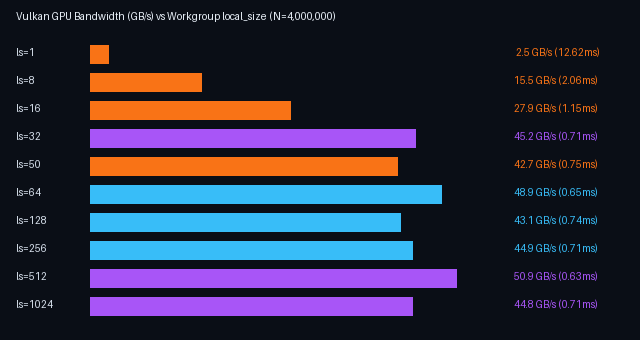

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
import vknumpy as vnp
from vknumpy import global_id_x

N = 4_000_000
a_np = np.arange(N, dtype=np.float32)
a_gpu = vnp.array(a_np)
out_gpu = vnp.zeros((N,), dtype=np.float32)
expected_head = a_np[:6] + 10.0

def make_kernel(ls: int):
    @vnp.kernel(local_size=(ls, 1, 1))
    def map_add_10(out, a, n: int):
        i = global_id_x()
        if i < n:
            out[i] = a[i] + 10.0
    return map_add_10

sizes = [1, 8, 16, 32, 50, 64, 128, 256, 512, 1024]
results = []

print(f"Benchmarking {N:,} float32 elements (32 MB read+write) across workgroup sizes:\n")
print(f"{"local_size":>10s} | {"workgroups":>10s} | {"time (ms)":>10s} | {"bandwidth":>12s} | status")
print("-" * 62)

for ls in sizes:
    k = make_kernel(ls)
    grid = (N + ls - 1) // ls
    k[grid](out_gpu, a_gpu, N)  # warmup + pipeline cache
    n_runs = 10 if ls < 16 else 30
    t0 = time.perf_counter()
    for _ in range(n_runs):
        k[grid](out_gpu, a_gpu, N)
    ms = (time.perf_counter() - t0) * 1000.0 / n_runs
    gb_s = (2 * N * 4) / (ms * 1e-3) / 1e9
    np.testing.assert_allclose(out_gpu.to_numpy()[:6], expected_head, atol=1e-5)
    results.append((ls, grid, ms, gb_s))
    print(f"{ls:10d} | {grid:10,d} | {ms:10.3f} | {gb_s:9.1f} GB/s | OK")

# Render bar chart of effective GPU memory bandwidth (GB/s) vs local_size
W, H = 640, 340
im = Image.new("RGB", (W, H), (10, 14, 22))
draw = ImageDraw.Draw(im)
draw.text((16, 10), f"Vulkan GPU Bandwidth (GB/s) vs Workgroup local_size (N={N:,})", fill=(235, 242, 250))
max_bw = max(r[3] for r in results) * 1.12
for idx, (ls, grid, ms, gb_s) in enumerate(results):
    y0 = 42 + idx * 28
    if ls in (64, 128, 256):
        col = (56, 189, 248)   # sweet spot (cyan)
    elif ls < 32 or (ls % 32 != 0):
        col = (249, 115, 22)   # underutilized wavefronts (orange)
    else:
        col = (168, 85, 247)   # valid multiple of 32 (violet)
    bw_px = int((gb_s / max_bw) * 410)
    draw.text((16, y0 + 4), f"ls={ls:<4d}", fill=(215, 224, 236))
    draw.rectangle([90, y0 + 3, 90 + max(2, bw_px), y0 + 21], fill=col)
    draw.text((512, y0 + 4), f"{gb_s:5.1f} GB/s ({ms:.2f}ms)", fill=col)
im